<a href="https://colab.research.google.com/github/Ziad-Gebril/Linear-Models-and-Support-Vector-Machines/blob/linear_reg/ML_assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORTS**

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

# **Part A**

In [45]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits,load_iris

diabetes = load_diabetes(scaled = False)
XD = diabetes.data
YD = diabetes.target

cancer = load_breast_cancer()
XC = cancer.data
YC = 1 - cancer.target    # flipping the data

digits = load_digits()
XDG = digits.data / 16  # dividing the digits data by 16
YDG = digits.target

iris = load_iris()
XI = iris.data
YI = iris.target

In [ ]:
XD_tr, XD_te, yD_tr, yD_te = train_test_split(XD, YD, test_size=0.2, random_state=42)
XD_tr, XD_va, yD_tr, yD_va = train_test_split(XD_tr, yD_tr, test_size=0.25, random_state=42)

XC_tr, XC_te, yC_tr, yC_te = train_test_split(XC, YC, test_size=0.2, random_state=42, stratify=YC)
XC_tr, XC_va, yC_tr, yC_va = train_test_split(XC_tr, yC_tr, test_size=0.25, random_state=42, stratify=yC_tr)

XDG_tr, XDG_te, yDG_tr, yDG_te = train_test_split(XDG, YDG, test_size=0.2, random_state=42, stratify=YDG)
XDG_tr, XDG_va, yDG_tr, yDG_va = train_test_split(XDG_tr, yDG_tr, test_size=0.25, random_state=42, stratify=yDG_tr)

XI_tr, XI_te, yI_tr, yI_te = train_test_split(XI, YI, test_size=0.2, random_state=42, stratify=YI)
XI_tr, XI_va, yI_tr, yI_va = train_test_split(XI_tr, yI_tr, test_size=0.25, random_state=42, stratify=yI_tr)

In [ ]:
for name, y_tr, y_va, y_te in [
    ("Cancer", yC_tr, yC_va, yC_te),
    ("Digits", yDG_tr, yDG_va, yDG_te),
    ("Iris", yI_tr, yI_va, yI_te)
]:
    print(f"\n{name}")
    print("Train:", np.unique(y_tr, return_counts=True))
    print("Validation:", np.unique(y_va, return_counts=True))
    print("Test:", np.unique(y_te, return_counts=True))


Cancer
Train: (array([0, 1]), array([214, 127]))
Validation: (array([0, 1]), array([71, 43]))
Test: (array([0, 1]), array([72, 42]))

Digits
Train: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Test: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

Iris
Train: (array([0, 1, 2]), array([30, 30, 30]))
Validation: (array([0, 1, 2]), array([10, 10, 10]))
Test: (array([0, 1, 2]), array([10, 10, 10]))


In [ ]:
print("Diabetes:", len(yD_tr), len(yD_va), len(yD_te))
print("Cancer:", len(yC_tr), len(yC_va), len(yC_te))
print("Digits:", len(yDG_tr), len(yDG_va), len(yDG_te))
print("Iris:", len(yI_tr), len(yI_va), len(yI_te))

Diabetes: 264 89 89
Cancer: 341 114 114
Digits: 1077 360 360
Iris: 90 30 30


In [ ]:
class S:
    pass

def Standardizer_fit(SS,X):
  SS.mean = np.mean(X,axis = 0)
  SS.std = np.std(X,axis = 0)


  n=len(SS.std)
  i=0
  while(i<n):
    if (SS.std[i]==0):
      SS.std[i] = 1
    i+=1

  return SS


def transform(SS, X):
      return (X - SS.mean) / SS.std   # z= (x-m)/o'


def add_bias(XX):
  one = np.ones((len(XX),1))
  X = np.column_stack((one,XX))
  return X

In [ ]:
# made the test with Ai
# Diabetes
scaler_D = S()
Standardizer_fit(scaler_D, XD_tr)

XD_tr = transform(scaler_D, XD_tr)
XD_va = transform(scaler_D, XD_va)
XD_te = transform(scaler_D, XD_te)


# Cancer
scaler_C = S()
Standardizer_fit(scaler_C, XC_tr)

XC_tr = transform(scaler_C, XC_tr)
XC_va = transform(scaler_C, XC_va)
XC_te = transform(scaler_C, XC_te)


# Iris
scaler_I = S()
Standardizer_fit(scaler_I, XI_tr)

XI_tr = transform(scaler_I, XI_tr)
XI_va = transform(scaler_I, XI_va)
XI_te = transform(scaler_I, XI_te)


for name, X_tr, X_va, X_te in [
    ("Diabetes", XD_tr, XD_va, XD_te),
    ("Cancer", XC_tr, XC_va, XC_te),
    ("Iris", XI_tr, XI_va, XI_te)
]:
    print(f"\n{name}")
    print("Train mean:", np.round(X_tr.mean(axis=0), 6))
    print("Train std:", np.round(X_tr.std(axis=0), 6))


Diabetes
Train mean: [-0.  0. -0. -0. -0. -0. -0. -0. -0.  0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Cancer
Train mean: [-0.  0. -0. -0. -0. -0.  0. -0.  0.  0.  0. -0.  0.  0.  0.  0. -0.  0.
  0.  0. -0.  0. -0. -0.  0. -0.  0.  0. -0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris
Train mean: [ 0.  0. -0.  0.]
Train std: [1. 1. 1. 1.]


In [ ]:
def mse(y_t, y_p):
  errors = y_t - y_p
  return np.mean(np.array(errors) ** 2)


def rmse(y_t, y_p):
  return np.sqrt(mse(y_t, y_p))


def r2(y_t, y_p):
  s1= np.sum((y_t-y_p)**2) # comparing each one to the predicted one
  s2 = np.sum(( np.mean(y_t)-y_t)**2) # comparing each one to the mean of all of them
  return 1-(s1/s2)


def accuracy(y_t, pred):
  T= np.sum(y_t == pred)
  total = len(y_t)
  return T/total

#def conf_matrix(y, pred):
 # classesT =np.unique(y)
  #CM = np.zeros((K,K))
##
 # classesP =np.unique(y)
 #
  #i=0
#
 # while(i<K):
  #  TR = np.where(classesT == y[i])[0][0]
   # PR = np.where(classesP == pred[i])[0][0]
    #CM[TR][PR] += 1
#
 #   i+=1
#
 # return CM\\

def confusion_matrix(y, pred, K):
    CM = np.bincount(
        K * y + pred,
        minlength=K * K
    ).reshape(K, K)

    return CM

In [ ]:
def precision(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  PR = np.zeros(n)

  while(i<n):
    if np.sum(CM[:, i]) == 0:
      PR[i] = 0
      # Precision = 0 for a class that is never predicted
    else:
      PR[i] = d[i]/np.sum(CM[:, i]) # to take only one column
    i+=1
  return PR

def recall(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  RC = np.zeros(n)

  while(i<n):
    if np.sum(CM[i, :]) == 0:
      RC[i] = 0
      # recall = 0 for a class that is never Existed
    else:
      RC[i] = d[i]/np.sum(CM[i, :]) # to take only one row
    i+=1
  return RC


def F1(CM):
  P = precision(CM)
  R = recall(CM)

  n=len(P)
  i=0
  F = np.zeros(n)

  while(i<n):
    NOM = P[i]*R[i]
    DNOM = P[i]+R[i]
    if DNOM == 0:
      F[i] = 0
    else:
      F[i]= 2*NOM/DNOM
    i+=1
  return F

In [ ]:
y_t = np.array([0, 1, 2, 0, 1])
y_p = np.array([0, 1, 0, 2, 1])

classes =np.unique(y_t)
n = len(classes)

CM = confusion_matrix(y_t, y_p, n)

macro_precision = np.mean(precision(CM))
macro_recall = np.mean(recall(CM))
macro_F1 = np.mean(F1(CM))


print("Precision:", precision(CM))
print("Macro Precision:", macro_precision)

print("Recall:", recall(CM))
print("Macro Recall:", macro_recall)

print("F1:", F1(CM))
print("Macro F1:", macro_F1)

Precision: [0.5 1.  0. ]
Macro Precision: 0.5
Recall: [0.5 1.  0. ]
Macro Recall: 0.5
F1: [0.5 1.  0. ]
Macro F1: 0.5


In [ ]:
print(CM)
print(precision(CM))
print(F1(CM))

[[1 0 1]
 [0 2 0]
 [1 0 0]]
[0.5 1.  0. ]
[0.5 1.  0. ]


In [ ]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

N = 500
K = 4

# Regression
y_reg = rng.normal(size=N)
pred_reg = rng.normal(size=N)

# Classification
y = rng.integers(0, K, size=N)
pred = rng.integers(0, K, size=N)

In [ ]:
np.testing.assert_allclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

print("Regression metrics: PASSED")

Regression metrics: PASSED


In [ ]:
CM = confusion_matrix(y, pred, K)

CM_ref = sk_confusion_matrix(
    y, pred,
    labels=np.arange(K)
)

np.testing.assert_array_equal(CM, CM_ref)

print("Confusion matrix: PASSED")

Confusion matrix: PASSED


In [ ]:
P_ref, R_ref, F_ref, _ = precision_recall_fscore_support(
    y, pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)

np.testing.assert_allclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    precision(CM), P_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    recall(CM), R_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    F1(CM), F_ref,
    atol=1e-12, rtol=0
)

print("Classification metrics: PASSED")

Classification metrics: PASSED


In [ ]:
np.testing.assert_allclose(
    np.mean(precision(CM)),
    np.mean(P_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(recall(CM)),
    np.mean(R_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(F1(CM)),
    np.mean(F_ref),
    atol=1e-12, rtol=0
)

print("Macro averages: PASSED")

Macro averages: PASSED


In [ ]:
def grad_check(f, grad, w, eps=1e-5):
    w = np.array(w, dtype=float)

    g_analytic = grad(w).flatten()
    g_numeric = np.zeros(w.size)

    # Select entries to check
    rng = np.random.default_rng(42)

    if w.size > 100:
        indices = rng.choice(w.size, size=100, replace=False)
    else:
        indices = np.arange(w.size)

    # Central differences
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        g_numeric[i] = (f(w_plus) - f(w_minus)) / (2 * eps)

    # Compare only the selected entries
    g_a = g_analytic[indices]
    g_n = g_numeric[indices]

    numerator = np.linalg.norm(g_a - g_n)
    denominator = max(
        np.linalg.norm(g_a),
        np.linalg.norm(g_n),
        1e-12
    )

    return numerator / denominator

In [ ]:
# a test fro grad from the AI

def test_f(w):
    return np.sum(w**2)

def test_grad(w):
    return 2*w

rng = np.random.default_rng(42)
w = rng.normal(0, 0.1, size=5)

error = grad_check(test_f, test_grad, w)

print("Relative error:", error)
print("Passed:", error < 1e-6)

Relative error: 1.1752888136783617e-12
Passed: True


# **Part B**

In [46]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import mean_squared_error, r2_score

diabetes_B = load_diabetes(scaled=False)
X_raw = diabetes_B.data.astype(float)
y_all = diabetes_B.target.astype(float)
feature_names = list(diabetes_B.feature_names)

X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X_raw, y_all, test_size=0.20, random_state=42
)
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    X_train_raw, y_train, test_size=0.25, random_state=42
)

# Fit preprocessing on training data only.
x_mean = X_train_raw.mean(axis=0)
x_std = X_train_raw.std(axis=0)
x_std[x_std == 0] = 1.0
X_train = (X_train_raw - x_mean) / x_std
X_val = (X_val_raw - x_mean) / x_std
X_test = (X_test_raw - x_mean) / x_std
N_train = len(y_train)

print("Split sizes:", len(y_train), len(y_val), len(y_test))
print("Train means:", np.round(X_train.mean(axis=0), 10))
print("Train stds:", np.round(X_train.std(axis=0), 10))

Split sizes: 264 89 89
Train means: [-0.  0. -0. -0. -0. -0.  0. -0.  0. -0.]
Train stds: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [47]:
def add_bias(X):
    X = np.asarray(X, dtype=float)
    return np.column_stack((np.ones(X.shape[0]), X))

def normal_equation(X, y):
    Xb = add_bias(X)
    return np.linalg.solve(Xb.T @ Xb, Xb.T @ y)

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

Xb_train, Xb_val, Xb_test = map(add_bias, (X_train, X_val, X_test))
w_star = normal_equation(X_train, y_train)

pred_train = Xb_train @ w_star
pred_val = Xb_val @ w_star
pred_test = Xb_test @ w_star
train_rmse = rmse(y_train, pred_train)
val_rmse = rmse(y_val, pred_val)
test_rmse = rmse(y_test, pred_test)
test_r2 = r2_score(y_test, pred_test)
condition_number = np.linalg.cond(Xb_train.T @ Xb_train)

display(pd.DataFrame({"Feature": ["bias"] + feature_names, "Weight": w_star}))
print(f"Train RMSE: {train_rmse:.4f}")
print(f"Validation RMSE: {val_rmse:.4f}")
print(f"Test RMSE: {test_rmse:.4f}")
print(f"Test R2: {test_r2:.6f}")
print(f"Condition number: {condition_number:.2f}")

linear_model = LinearRegression().fit(X_train, y_train)
w_sklearn = np.r_[linear_model.intercept_, linear_model.coef_]
print("Maximum difference from LinearRegression:",
      np.max(np.abs(w_star - w_sklearn)))
print("Weights match within 1e-6:",
      np.allclose(w_star, w_sklearn, atol=1e-6, rtol=0))

,Feature,Weight
0,bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


Train RMSE: 54.6104
Validation RMSE: 51.1937
Test RMSE: 54.1564
Test R2: 0.446426
Condition number: 505.71
Maximum difference from LinearRegression: 1.1510792319313623e-12
Weights match within 1e-6: True


**Task 5 interpretation:** Compare the signs and magnitudes of `s1`, `s2`, and `bmi` in the coefficient table. Each coefficient is a partial effect with the other features held fixed. Since the serum measurements are correlated, changing one feature while holding all the others fixed may describe an unusual patient, so individual coefficients can be unstable and should not be treated as independent causal effects.

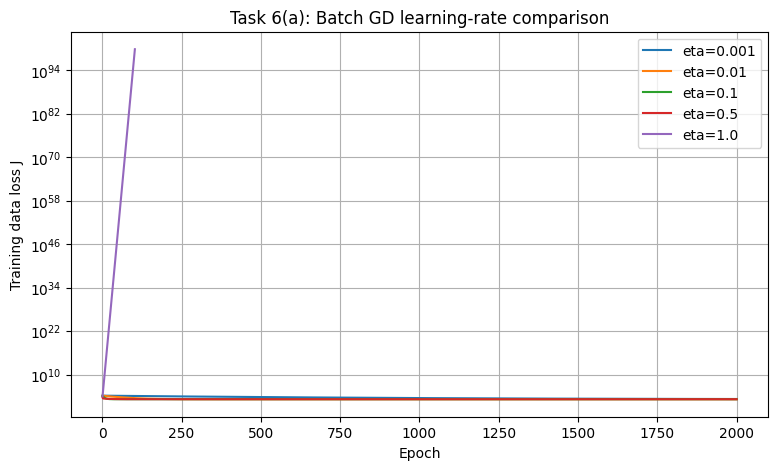

,eta,Final J,Final relative distance,First epoch below 1e-3,Diverged
0,0.001,1723.402889,4.051131e-01,not reached,False
1,0.010,1503.686676,3.345214e-01,not reached,False
2,0.100,1491.892636,8.179229e-02,not reached,False
3,0.500,1491.145907,1.546262e-04,1524,False
4,1.000,inf,1.068168e+48,not reached,True


In [48]:
def data_loss(Xb, y, w):
    residual = Xb @ w - y
    return float(residual @ residual / (2 * len(y)))

def gradient(Xb, y, w):
    return Xb.T @ (Xb @ w - y) / len(y)

def batch_gd(Xb, y, eta, epochs, reference_w=None):
    w = np.zeros(Xb.shape[1])
    losses = np.empty(epochs)
    distances = np.full(epochs, np.nan)
    first_below = None
    for epoch in range(epochs):
        w -= eta * gradient(Xb, y, w)
        losses[epoch] = data_loss(Xb, y, w)
        if reference_w is not None:
            d = np.linalg.norm(w-reference_w) / max(np.linalg.norm(reference_w), 1e-12)
            distances[epoch] = d
            if first_below is None and d < 1e-3:
                first_below = epoch + 1
        if not np.isfinite(losses[epoch]) or losses[epoch] > 1e100:
            losses[epoch:] = np.inf
            break
    return w, losses, distances, first_below

etas = [0.001, 0.01, 0.1, 0.5, 1.0]
gd_results = {}
plt.figure(figsize=(9, 5))
for eta in etas:
    result = batch_gd(Xb_train, y_train, eta, 2000, w_star)
    gd_results[eta] = result
    valid = np.isfinite(result[1]) & (result[1] > 0)
    plt.plot(np.arange(1, 2001)[valid], result[1][valid], label=f"eta={eta}")
plt.yscale("log")
plt.xlabel("Epoch"); plt.ylabel("Training data loss J")
plt.title("Task 6(a): Batch GD learning-rate comparison")
plt.legend(); plt.grid(True); plt.show()

rows = []
for eta, result in gd_results.items():
    finite_d = result[2][np.isfinite(result[2])]
    rows.append({
        "eta": eta,
        "Final J": result[1][-1],
        "Final relative distance": finite_d[-1] if len(finite_d) else np.inf,
        "First epoch below 1e-3": result[3] if result[3] is not None else "not reached",
        "Diverged": (not np.all(np.isfinite(result[1])) or result[1][-1] > 1e10)
    })
display(pd.DataFrame(rows))

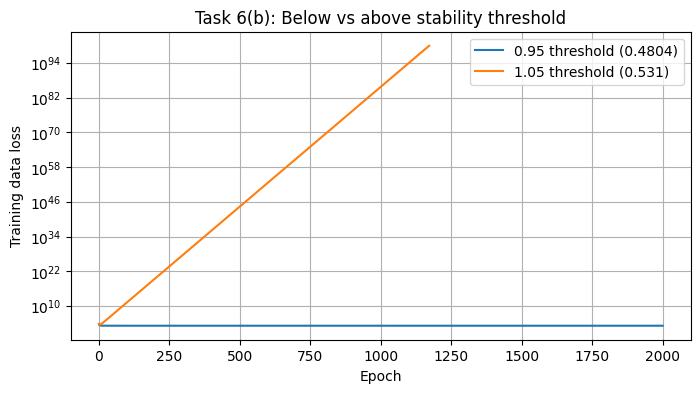

lambda_max: 3.9547550320503744
2 / lambda_max: 0.5057203249737277
Loss below threshold: 1491.1459097339757
Loss above threshold: inf


In [49]:
H = Xb_train.T @ Xb_train / N_train
lambda_max = np.linalg.eigvalsh(H).max()
threshold = 2.0 / lambda_max
eta_below, eta_above = 0.95 * threshold, 1.05 * threshold
below = batch_gd(Xb_train, y_train, eta_below, 2000, w_star)
above = batch_gd(Xb_train, y_train, eta_above, 2000, w_star)

plt.figure(figsize=(8, 4))
for label, result in [(f"0.95 threshold ({eta_below:.4g})", below),
                      (f"1.05 threshold ({eta_above:.4g})", above)]:
    valid = np.isfinite(result[1]) & (result[1] > 0)
    plt.plot(np.arange(1, 2001)[valid], result[1][valid], label=label)
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Training data loss")
plt.title("Task 6(b): Below vs above stability threshold")
plt.legend(); plt.grid(True); plt.show()
print("lambda_max:", lambda_max)
print("2 / lambda_max:", threshold)
print("Loss below threshold:", below[1][-1])
print("Loss above threshold:", above[1][-1])

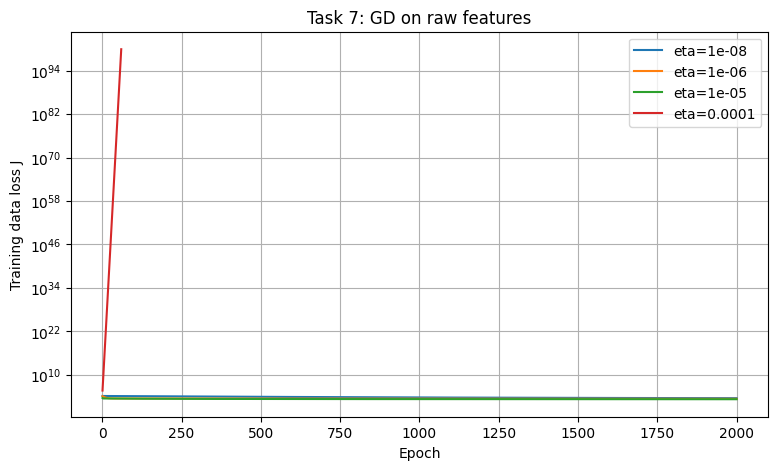

,Features,Condition number,2 / lambda_max
0,Standardized,5.057061e+02,0.505720
1,Raw,5.577847e+07,0.000027


,eta,Final J,Diverged
0,1.000000e-08,3583.532102,False
1,1.000000e-06,2388.752582,False
2,1.000000e-05,1827.534910,False
3,1.000000e-04,inf,True


In [50]:
Xb_raw = add_bias(X_train_raw)
H_raw = Xb_raw.T @ Xb_raw / N_train
lambda_max_raw = np.linalg.eigvalsh(H_raw).max()
threshold_raw = 2 / lambda_max_raw
threshold_scaled = 2 / np.linalg.eigvalsh(Xb_train.T @ Xb_train / N_train).max()

raw_etas = [1e-8, 1e-6, 1e-5, 1e-4]
raw_results = {}
plt.figure(figsize=(9, 5))
for eta in raw_etas:
    result = batch_gd(Xb_raw, y_train, eta, 2000)
    raw_results[eta] = result
    valid = np.isfinite(result[1]) & (result[1] > 0)
    plt.plot(np.arange(1, 2001)[valid], result[1][valid], label=f"eta={eta:g}")
plt.yscale("log"); plt.xlabel("Epoch"); plt.ylabel("Training data loss J")
plt.title("Task 7: GD on raw features"); plt.legend(); plt.grid(True); plt.show()

display(pd.DataFrame({
    "Features": ["Standardized", "Raw"],
    "Condition number": [np.linalg.cond(Xb_train.T @ Xb_train),
                         np.linalg.cond(Xb_raw.T @ Xb_raw)],
    "2 / lambda_max": [threshold_scaled, threshold_raw]
}))
display(pd.DataFrame([{
    "eta": eta, "Final J": result[1][-1],
    "Diverged": (not np.all(np.isfinite(result[1])) or result[1][-1] > 1e10)
} for eta, result in raw_results.items()]))

**Task 7 interpretation:** Standardization puts feature columns on comparable scales and usually reduces the condition number of \(X_b^TX_b\). A smaller condition number means the eigenvalues are less spread out, so gradient descent progresses at more similar rates in different directions. The largest eigenvalue sets the stability limit \(2/\lambda_{\max}\), meaning raw features can require a much smaller learning rate. A smaller usable learning rate requires more epochs, while a rate above the limit makes the loss diverge.

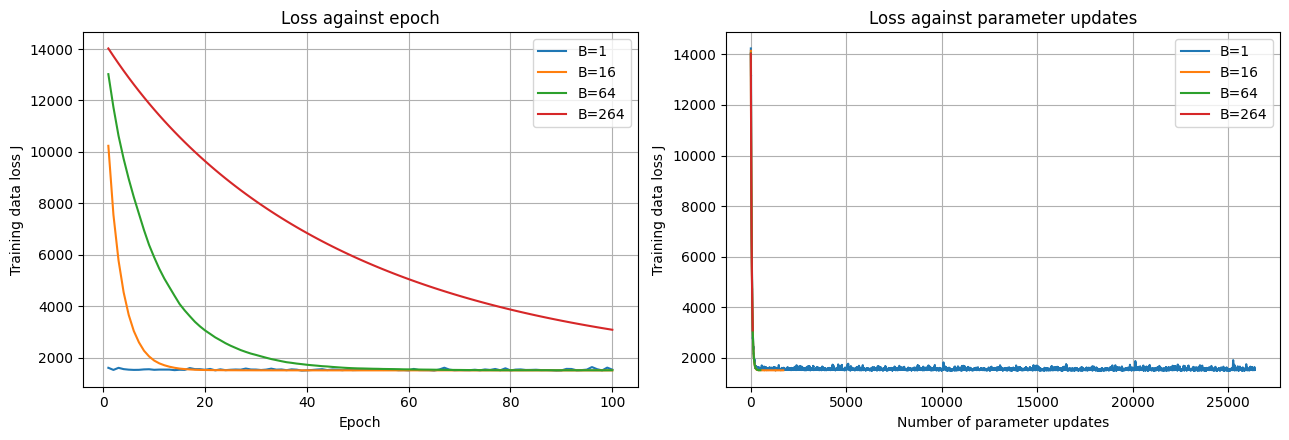

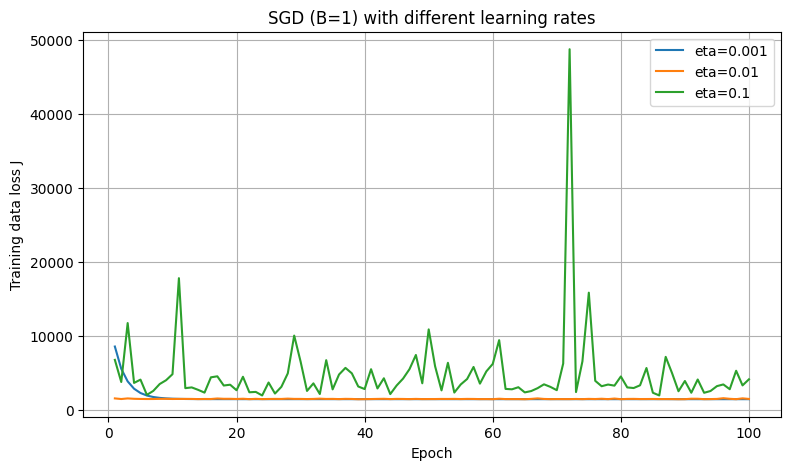

,Batch size,Final training loss,Parameter updates
0,1,1534.808385,26400
1,16,1505.665099,1700
2,64,1511.375336,500
3,264,3085.440479,100


In [51]:
def minibatch_gd(Xb, y, eta, epochs, batch_size, seed=42):
    rng = np.random.default_rng(seed)
    w = np.zeros(Xb.shape[1])
    epoch_losses, update_numbers, update_losses = [], [], []
    update_count = 0
    for _ in range(epochs):
        order = rng.permutation(len(y))
        for start in range(0, len(y), batch_size):
            idx = order[start:start + batch_size]
            w -= eta * gradient(Xb[idx], y[idx], w)
            update_count += 1
            update_numbers.append(update_count)
            update_losses.append(data_loss(Xb, y, w))
        epoch_losses.append(data_loss(Xb, y, w))
    return w, np.array(epoch_losses), np.array(update_numbers), np.array(update_losses)

batch_sizes = [1, 16, 64, N_train]
batch_results = {
    B: minibatch_gd(Xb_train, y_train, 0.01, 100, B, seed=42)
    for B in batch_sizes
}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for B, result in batch_results.items():
    axes[0].plot(np.arange(1, 101), result[1], label=f"B={B}")
    axes[1].plot(result[2], result[3], label=f"B={B}")
axes[0].set(title="Loss against epoch", xlabel="Epoch", ylabel="Training data loss J")
axes[1].set(title="Loss against parameter updates",
            xlabel="Number of parameter updates", ylabel="Training data loss J")
for ax in axes:
    ax.legend(); ax.grid(True)
plt.tight_layout(); plt.show()

plt.figure(figsize=(9, 5))
sgd_results = {}
for eta in [0.001, 0.01, 0.1]:
    result = minibatch_gd(Xb_train, y_train, eta, 100, 1, seed=42)
    sgd_results[eta] = result
    plt.plot(np.arange(1, 101), result[1], label=f"eta={eta}")
plt.xlabel("Epoch"); plt.ylabel("Training data loss J")
plt.title("SGD (B=1) with different learning rates")
plt.legend(); plt.grid(True); plt.show()

display(pd.DataFrame([{
    "Batch size": B, "Final training loss": result[1][-1],
    "Parameter updates": len(result[2])
} for B, result in batch_results.items()]))

**Task 8 interpretation:** A larger batch gives a smoother gradient estimate, while \(B=1\) is noisier because each update uses only one example. Per epoch, full-batch GD can make strong progress because its one update uses the complete dataset. Per update, smaller batches are cheaper, so they may make useful progress sooner; the preferred batch size depends on whether we compare epochs, updates, or computation time. Increasing the SGD learning rate generally makes fluctuations around the minimum larger.

Worked example ridge weights: [2.13333333 0.6       ]
Degree-2 feature count: 64
Degree-2 condition number: 1289356232.45045


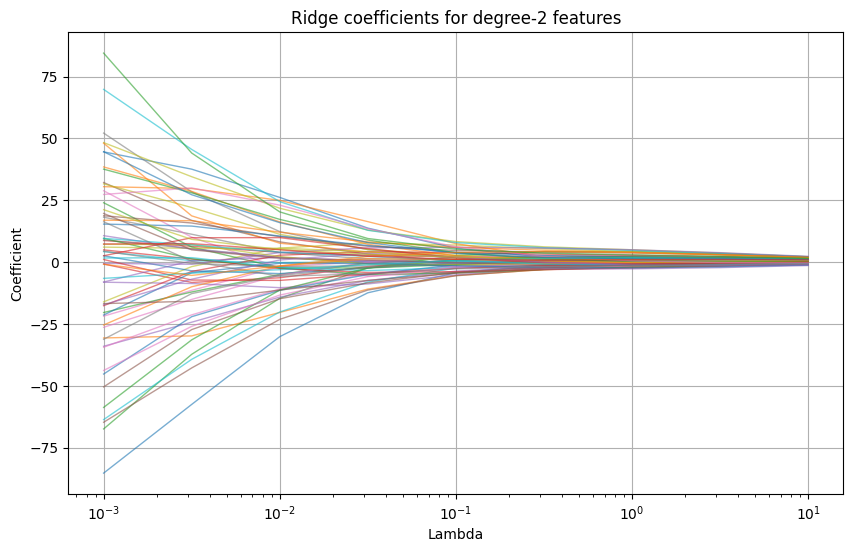

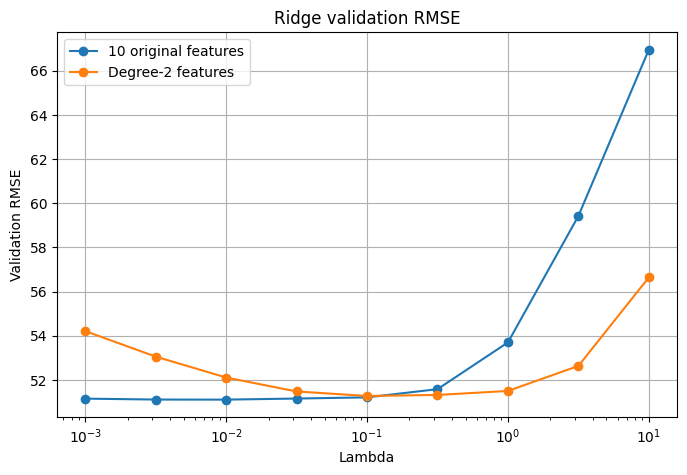

,Feature set,Best lambda,Validation RMSE,Test RMSE at best lambda,Test RMSE at lambda=0
0,10 original,0.01,51.104749,53.958452,54.156413
1,Degree-2,0.10,51.270640,53.615580,62.133373


In [52]:
def ridge_closed_form(Xb, y, lam):
    penalty = np.eye(Xb.shape[1])
    penalty[0, 0] = 0.0
    return np.linalg.solve(
        Xb.T @ Xb / len(y) + lam * penalty,
        Xb.T @ y / len(y)
    )

def ridge_gradient(Xb, y, w, lam):
    g = gradient(Xb, y, w)
    g[1:] += lam * w[1:]
    return g

# Assignment worked example: expected approximately [2.1333, 0.6].
X_toy = np.array([[1.], [2.], [3.]])
y_toy = np.array([2., 3., 5.])
print("Worked example ridge weights:", ridge_closed_form(add_bias(X_toy), y_toy, 1.0))

lambdas = np.r_[0.0, np.logspace(-3, 1, 9)]
ridge_original = {}
for lam in lambdas:
    w = ridge_closed_form(Xb_train, y_train, lam)
    ridge_original[lam] = {
        "weights": w, "val_rmse": rmse(y_val, Xb_val @ w),
        "test_rmse": rmse(y_test, Xb_test @ w)
    }

# Degree-2 expansion: x_i and x_i*x_j for i <= j.
# Drop sex^2 because sex is coded 1/2 and sex^2 is redundant with sex and bias.
def degree2_features(X):
    cols = [X[:, j] for j in range(X.shape[1])]
    names = list(feature_names)
    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            if feature_names[i] == "sex" and feature_names[j] == "sex":
                continue
            cols.append(X[:, i] * X[:, j])
            names.append(f"{feature_names[i]}*{feature_names[j]}")
    return np.column_stack(cols), names

X2_train_raw, degree2_names = degree2_features(X_train_raw)
X2_val_raw, _ = degree2_features(X_val_raw)
X2_test_raw, _ = degree2_features(X_test_raw)
x2_mean = X2_train_raw.mean(axis=0)
x2_std = X2_train_raw.std(axis=0)
x2_std[x2_std == 0] = 1.0
X2_train = (X2_train_raw - x2_mean) / x2_std
X2_val = (X2_val_raw - x2_mean) / x2_std
X2_test = (X2_test_raw - x2_mean) / x2_std
X2b_train, X2b_val, X2b_test = map(add_bias, (X2_train, X2_val, X2_test))
print("Degree-2 feature count:", X2_train.shape[1])
print("Degree-2 condition number:", np.linalg.cond(X2b_train.T @ X2b_train))

ridge_degree2 = {}
for lam in lambdas:
    w = ridge_closed_form(X2b_train, y_train, lam)
    ridge_degree2[lam] = {
        "weights": w, "val_rmse": rmse(y_val, X2b_val @ w),
        "test_rmse": rmse(y_test, X2b_test @ w)
    }

plt.figure(figsize=(10, 6))
for j, name in enumerate(degree2_names, start=1):
    plt.plot(lambdas[1:],
             [ridge_degree2[lam]["weights"][j] for lam in lambdas[1:]],
             alpha=0.6, linewidth=1)
plt.xscale("log"); plt.xlabel("Lambda"); plt.ylabel("Coefficient")
plt.title("Ridge coefficients for degree-2 features")
plt.grid(True); plt.show()

plt.figure(figsize=(8, 5))
plt.plot(lambdas[1:],
         [ridge_original[lam]["val_rmse"] for lam in lambdas[1:]],
         marker="o", label="10 original features")
plt.plot(lambdas[1:],
         [ridge_degree2[lam]["val_rmse"] for lam in lambdas[1:]],
         marker="o", label="Degree-2 features")
plt.xscale("log"); plt.xlabel("Lambda"); plt.ylabel("Validation RMSE")
plt.title("Ridge validation RMSE"); plt.legend(); plt.grid(True); plt.show()

best_original = min(ridge_original, key=lambda z: ridge_original[z]["val_rmse"])
best_degree2 = min(ridge_degree2, key=lambda z: ridge_degree2[z]["val_rmse"])
display(pd.DataFrame([
    {"Feature set": "10 original", "Best lambda": best_original,
     "Validation RMSE": ridge_original[best_original]["val_rmse"],
     "Test RMSE at best lambda": ridge_original[best_original]["test_rmse"],
     "Test RMSE at lambda=0": ridge_original[0.0]["test_rmse"]},
    {"Feature set": "Degree-2", "Best lambda": best_degree2,
     "Validation RMSE": ridge_degree2[best_degree2]["val_rmse"],
     "Test RMSE at best lambda": ridge_degree2[best_degree2]["test_rmse"],
     "Test RMSE at lambda=0": ridge_degree2[0.0]["test_rmse"]}
]))

In [53]:
# Task 9 verification: GD, closed form, and sklearn Ridge.
lam_check, eta_check, epochs_check = 0.1, 0.4, 3000
w_ridge_closed = ridge_closed_form(Xb_train, y_train, lam_check)
w_ridge_gd = np.zeros(Xb_train.shape[1])
for _ in range(epochs_check):
    w_ridge_gd -= eta_check * ridge_gradient(
        Xb_train, y_train, w_ridge_gd, lam_check
    )
gd_relative_distance = (
    np.linalg.norm(w_ridge_gd - w_ridge_closed) / np.linalg.norm(w_ridge_closed)
)

ridge_sklearn = Ridge(alpha=lam_check * N_train).fit(X_train, y_train)
w_ridge_sklearn = np.r_[ridge_sklearn.intercept_, ridge_sklearn.coef_]
print("GD vs closed form relative distance:", gd_relative_distance)
print("Closed form vs sklearn max difference:",
      np.max(np.abs(w_ridge_closed - w_ridge_sklearn)))
print("GD check passed:", gd_relative_distance < 1e-6)
print("Sklearn check passed:",
      np.allclose(w_ridge_closed, w_ridge_sklearn, atol=1e-6, rtol=0))

GD vs closed form relative distance: 8.35921888397673e-16
Closed form vs sklearn max difference: 1.5631940186722204e-13
GD check passed: True
Sklearn check passed: True


**Task 9 interpretation:** Ridge may help little with the 10 original features because there are 264 training examples and only 10 inputs. The degree-2 expansion has 64 features, so it is more flexible relative to the number of training examples and more exposed to correlated or redundant columns. L2 regularization shrinks coefficients and can improve validation performance in this expanded model. The bias is not penalized because it sets the overall prediction level; shrinking it would unnecessarily force the baseline toward zero.

In [54]:
comparison_rows = []

def record_result(name, w, elapsed, reference):
    comparison_rows.append({
        "Method": name,
        "Test RMSE": rmse(y_test, Xb_test @ w),
        "Relative distance": np.linalg.norm(w-reference) / max(np.linalg.norm(reference), 1e-12),
        "Fit time (seconds)": elapsed
    })

start = time.perf_counter()
w_normal = normal_equation(X_train, y_train)
record_result("Normal equation (scratch)", w_normal,
              time.perf_counter()-start, w_star)

start = time.perf_counter()
w_batch = batch_gd(Xb_train, y_train, 0.5, 2000)[0]
record_result("Batch GD (eta=0.5)", w_batch,
              time.perf_counter()-start, w_star)

start = time.perf_counter()
w_mini = minibatch_gd(Xb_train, y_train, 0.01, 100, 16, seed=42)[0]
record_result("Mini-batch GD (B=16, eta=0.01)", w_mini,
              time.perf_counter()-start, w_star)

lam_compare = 0.1
w_ridge_ref = ridge_closed_form(Xb_train, y_train, lam_compare)
start = time.perf_counter()
w_ridge_scratch = ridge_closed_form(Xb_train, y_train, lam_compare)
record_result("Ridge (scratch, lambda=0.1)", w_ridge_scratch,
              time.perf_counter()-start, w_ridge_ref)

start = time.perf_counter()
lr_lib = LinearRegression().fit(X_train, y_train)
w_lr_lib = np.r_[lr_lib.intercept_, lr_lib.coef_]
record_result("sklearn LinearRegression", w_lr_lib,
              time.perf_counter()-start, w_star)

start = time.perf_counter()
ridge_lib = Ridge(alpha=lam_compare*N_train).fit(X_train, y_train)
w_ridge_lib = np.r_[ridge_lib.intercept_, ridge_lib.coef_]
record_result("sklearn Ridge", w_ridge_lib,
              time.perf_counter()-start, w_ridge_ref)

for eta0 in [0.001, 0.01, 0.1]:
    start = time.perf_counter()
    model = SGDRegressor(penalty=None, learning_rate="constant", eta0=eta0,
                         max_iter=1000, tol=None, random_state=42)
    model.fit(X_train, y_train)
    w_sgd = np.r_[model.intercept_[0], model.coef_]
    record_result(f"SGDRegressor eta0={eta0}", w_sgd,
                  time.perf_counter()-start, w_star)

display(pd.DataFrame(comparison_rows))
print("Normal equation vs LinearRegression max difference:",
      np.max(np.abs(w_normal-w_lr_lib)))
print("Ridge scratch vs sklearn max difference:",
      np.max(np.abs(w_ridge_ref-w_ridge_lib)))

,Method,Test RMSE,Relative distance,Fit time (seconds)
0,Normal equation (scratch),54.156413,0.000000e+00,0.000417
1,Batch GD (eta=0.5),54.156254,1.546262e-04,0.042446
2,"Mini-batch GD (B=16, eta=0.01)",53.895449,3.421471e-01,0.038904
3,"Ridge (scratch, lambda=0.1)",53.708925,0.000000e+00,0.000196
4,sklearn LinearRegression,54.156413,9.868552e-15,0.001353
5,sklearn Ridge,53.708925,1.522184e-15,0.001439
6,SGDRegressor eta0=0.001,54.088486,4.976050e-02,0.018462
7,SGDRegressor eta0=0.01,54.898061,5.031993e-02,0.017243
8,SGDRegressor eta0=0.1,71.449348,3.949685e-01,0.017216


Normal equation vs LinearRegression max difference: 1.1510792319313623e-12
Ridge scratch vs sklearn max difference: 1.5631940186722204e-13


**Task 10 interpretation:** The normal equation and `LinearRegression` solve the same least-squares problem, so their coefficients should agree up to floating-point precision. The closed-form Ridge and scikit-learn Ridge results should also agree when `alpha=lambda*N_train`, which matches the assignment's mean-loss objective to scikit-learn's summed-loss convention. Gradient descent and SGD may differ after a fixed number of updates because their results depend on learning rate, batch order, solver details, and stopping rules.